# J=1, mJ=0 and mJ=1: post-lens position and velocity distributions

This notebook uses the full beamline and CuPy source draw from `full_beamline_lens_exit_velocity_scan.ipynb`. It samples every molecule crossing planes 0.5 m and 1.0 m after the lens end, then plots position and transverse velocity PDFs with Gaussian fits for the two J=1 states. The scan uses 30 million initial particles **per voltage and per state** at 0, 20, 23, 25, 27, and 30 kV. Propagation stops after the second sampling plane, where the requested distributions are recorded. Select the `centrex-trajectories-gpu` environment.

The J=1 Stark curves are obtained by diagonalizing the TlF rigid-rotor Hamiltonian for each mJ and fitting the resulting energy curve over 0–3 MV/m. The rotational constant and dipole moment match `centrex_tlf.hamiltonian.constants.XConstants`. The same calculation reproduces the existing J=2, mJ=0 fit used by the preceding notebook to within 0.06% in Stark shift over this range. The mJ=1 curve also describes mJ=−1 in zero magnetic field. Nuclear-spin hyperfine splittings are omitted in this rotational model.

In [ ]:
import gc
import pickle
from pathlib import Path

import cupy as cp
import h5py
import matplotlib.pyplot as plt
import numpy as np
import numpy.typing as npt

from centrex_trajectories import (
    Coordinates, Gravity, PropagationOptions, PropagationType, Velocities,
    propagate_trajectories,
)
from centrex_trajectories.beamline_objects import (
    Bore, CircularAperture, ElectrostaticQuadrupoleLens,
    PlateElectrodes, RectangularAperture, Section,
)
from centrex_trajectories.particles import TlF

DATA_DIR = Path.cwd() if (Path.cwd() / "fit_coeffs.pkl").exists() else Path.cwd() / "simulation"
assert (DATA_DIR / "fit_coeffs.pkl").exists(), "Run from the repository root or simulation directory"
with (DATA_DIR / "inverse_abel_pdf_F_r_short.pkl").open("rb") as f:
    interp_origin_pdf = pickle.load(f)

particle = TlF()
gravity = Gravity(0, -9.81 * particle.mass, 0)
options = PropagationOptions(verbose=False, n_cores=24)
in_to_m = 25.4e-3
distance_lens_bbexit = 36 * in_to_m
lens_chamber_length = (24 + 5 / 8) * in_to_m
lens_electrode_length = 0.6
rc_aperture_radius = 0.011
print("CUDA device:", cp.cuda.runtime.getDeviceProperties(0)["name"])

## TlF J=1 Stark curves

In [ ]:
from scipy.constants import h

# XConstants: B_rot = 6.689873 GHz - 45.0843 MHz / 2; dipole = 4.2282 Debye.
B_ROT_HZ = 6.689873e9 - 45.0843e6 / 2
DIPOLE_C_M = 4.2282 * 3.3356409519815204e-30
E_MAX = 3.0e6  # V/m, above 2*30 kV / 0.022225 m at the lens bore
E_GRID = np.linspace(0, E_MAX, 601)

def rigid_rotor_energy(J, mJ, fields, J_max=12):
    js = np.arange(abs(mJ), J_max + 1)
    diagonal = h * B_ROT_HZ * js * (js + 1)
    coupling = np.sqrt(((js[:-1] + 1)**2 - mJ**2) /
                       ((2 * js[:-1] + 1) * (2 * js[:-1] + 3)))
    energies = np.empty(len(fields), dtype=float)
    for i, field in enumerate(fields):
        matrix = np.diag(diagonal)
        matrix += np.diag(-DIPOLE_C_M * field * coupling, 1)
        matrix += np.diag(-DIPOLE_C_M * field * coupling, -1)
        energies[i] = np.linalg.eigvalsh(matrix)[J - abs(mJ)]
    return energies

def fit_stark_curve(J, mJ):
    energy = rigid_rotor_energy(J, mJ, E_GRID)
    u = E_GRID / E_MAX
    degrees = np.arange(2, 12)
    design = np.column_stack([u**degree for degree in degrees])
    fitted, *_ = np.linalg.lstsq(design, energy - energy[0], rcond=None)
    coefficients = np.zeros(12, dtype=float)
    coefficients[0] = energy[0]
    coefficients[degrees] = fitted / E_MAX**degrees
    reconstructed = np.polynomial.polynomial.polyval(E_GRID, coefficients)
    force_error = np.max(np.abs(np.gradient(reconstructed - energy, E_GRID)))
    print(f"J={J}, mJ={mJ}: max Stark energy fit error "
          f"{np.max(np.abs(reconstructed-energy)):.2e} J; "
          f"max dU/dE error {force_error:.2e} J/(V/m)")
    return coefficients

STARK_COEFFS = {mJ: fit_stark_curve(1, mJ) for mJ in (0, 1)}
with (DATA_DIR / "fit_coeffs.pkl").open("rb") as f:
    previous_J2 = pickle.load(f)["mF0"]
J2_reference = rigid_rotor_energy(2, 0, E_GRID)
J2_previous = np.polynomial.polynomial.polyval(E_GRID, previous_J2)
relative_difference = np.max(np.abs((J2_reference-J2_reference[0]) -
                                    (J2_previous-J2_previous[0]))) / np.max(np.abs(J2_reference-J2_reference[0]))
print(f"J=2 reference Stark shift agreement: {relative_difference:.3%}")
assert relative_difference < 0.001
fit_coeff_mF0 = STARK_COEFFS[0]  # default for the geometry builder; changed for each state below


## Beamline geometry, including the two drift sampling sections

In [ ]:
fourK = Section(
    name="4K shield",
    objects=[CircularAperture(0, 0, 1.75 * in_to_m, in_to_m / 2)],
    start=0,
    stop=(1.75 + 0.25) * 0.0254,
    save_collisions=False,
    propagation_type=PropagationType.ballistic,
)
fourtyK = Section(
    name="40K shield",
    objects=[CircularAperture(0, 0, fourK.stop + 1.25 * in_to_m, in_to_m / 2)],
    start=fourK.stop,
    stop=fourK.stop + (1.25 + 0.25) * 0.0254,
    save_collisions=False,
    propagation_type=PropagationType.ballistic,
)
bbexit = Section(
    name="Beamsource Exit",
    objects=[CircularAperture(0, 0, fourtyK.stop + 2.5 * in_to_m, 2 * in_to_m)],
    start=fourtyK.stop,
    stop=fourtyK.stop + (2.5 + 0.75) * in_to_m,
    save_collisions=False,
    propagation_type=PropagationType.ballistic,
)
rc_entrance = Section(
    name="Rotational cooling entrance",
    objects=[CircularAperture(x=0, y=0, z=0.473 + 0.005, r=46.74 * 1e-3 / 2)],
    start=0.473,
    stop=0.473 + 0.01,
    save_collisions=False,
    propagation_type=PropagationType.ballistic,
)
rc = Section(
    name="Rotational cooling",
    objects=[CircularAperture(x=0, y=0, z=0.678, r=rc_aperture_radius)],
    start=0.473,
    stop=0.720,
    save_collisions=False,
    propagation_type=PropagationType.ballistic,
)
def build_sections(
    voltage: float,
    length: float = 0.6,
    radius: float = 0.022225,
    stark_potential: npt.NDArray[np.float64] = fit_coeff_mF0,
):
    """Build the full beamline section list for a given lens voltage.

    Returns (sections, eql) so the caller can introspect lens position.
    """
    lens_start = bbexit.stop + distance_lens_bbexit + (lens_chamber_length - length) / 2
    lens_stop = lens_start + length

    if voltage == 0:
        eql = Section(
            name="Electrostatic Lens",
            objects=[Bore(x=0, y=0, z=lens_start, length=length, radius=radius)],
            start=lens_start,
            stop=lens_stop,
            save_collisions=False,
        )
    else:
        eql = ElectrostaticQuadrupoleLens(
            name="Electrostatic Lens",
            objects=[Bore(x=0, y=0, z=lens_start, length=length, radius=radius)],
            start=lens_start,
            stop=lens_stop,
            V=voltage,
            R=radius,
            save_collisions=False,
            stark_potential=stark_potential,
            tilt=0.0,
        )

    lens_chamber_to_electrode = (53 + 19 + 1 / 4) * in_to_m
    distance_det = 7.9

    interaction = Section(
        name="Interaction",
        objects=[
            RectangularAperture(
                0,
                0,
                eql.stop + lens_chamber_to_electrode,
                2e-2,
                1,
            ),
            PlateElectrodes(
                x=0,
                y=0,
                z=eql.stop + lens_chamber_to_electrode,
                length=3,
                width=20e-2,
                separation=2e-2,
            ),
        ],
        start=eql.stop + lens_chamber_to_electrode - 0.5,
        stop=eql.stop + lens_chamber_to_electrode + 3.1,
        save_collisions=True,
        propagation_type=PropagationType.ballistic,
    )

    det = Section(
        name="Detection",
        objects=[
        ],
        start=distance_det - 1e-3,
        stop=distance_det + 1e-3,
        save_collisions=False,
        propagation_type=PropagationType.ballistic,
        force=None,
    )

    lens_plus_0p5m = Section(
        name="Lens + 0.5 m",
        objects=[],
        start=eql.stop,
        stop=eql.stop + 0.5,
        save_collisions=False,
        propagation_type=PropagationType.ballistic,
    )
    lens_plus_1p0m = Section(
        name="Lens + 1.0 m",
        objects=[],
        start=lens_plus_0p5m.stop,
        stop=eql.stop + 1.0,
        save_collisions=False,
        propagation_type=PropagationType.ballistic,
    )
    sections = [fourK, fourtyK, bbexit, rc_entrance, rc, eql,
                lens_plus_0p5m, lens_plus_1p0m, interaction, det]
    return sections, eql



## CuPy source distribution and state-specific HDF5 output

One HDF5 file per mJ state stores all lens exits and all crossings at 0.5 m and 1.0 m. The `index` field preserves the original source-particle index across planes. The simulation uses a single CuPy draw of 30 million initial particles for each state and voltage.

In [ ]:
N_TRAJECTORIES = 30_000_000  # drawn and propagated together for each voltage
VOLTAGES_KV = (0, 20, 23, 25, 27, 30)
SEED = 20261007
VZ_MEAN = 195.0
VZ_SIGMA = 17.0
SOURCE_SIGMA_VXY = 39.4
RUN_SIZE = f"{N_TRAJECTORIES // 1_000_000}m"
def state_path(mJ):
    return DATA_DIR / f"post_lens_planes_J1_mJ{mJ}_{RUN_SIZE}_gpu.h5"

STATE_MJ = 0
PLANES_H5 = state_path(STATE_MJ)

rs = np.linspace(0, 15e-3, 1000)
radial_pdf = 2 * np.pi * rs * np.asarray(interp_origin_pdf, dtype=float)
radial_cdf = np.cumsum(radial_pdf)
radial_cdf /= radial_cdf[-1]
cp_rs = cp.asarray(rs)
cp_radial_cdf = cp.asarray(radial_cdf)

def draw_initial(n, seed):
    cp.random.seed(seed)
    radius = cp.interp(cp.random.random(n), cp_radial_cdf, cp_rs)
    theta = cp.random.random(n) * (2 * cp.pi)
    origin = Coordinates(radius * cp.cos(theta), radius * cp.sin(theta), cp.zeros(n))
    vz = cp.random.normal(VZ_MEAN, VZ_SIGMA, n)
    outside = (vz <= 100) | (vz >= 300)
    while bool(cp.any(outside)):
        vz[outside] = cp.random.normal(VZ_MEAN, VZ_SIGMA, int(cp.count_nonzero(outside)))
        outside = (vz <= 100) | (vz >= 300)
    velocities = Velocities(cp.random.normal(0, SOURCE_SIGMA_VXY, n),
                            cp.random.normal(0, SOURCE_SIGMA_VXY, n), vz)
    assert all(isinstance(arr, cp.ndarray) for arr in
               (origin.x, origin.y, origin.z, velocities.vx, velocities.vy, velocities.vz))
    return origin, velocities

def create_table(group, names):
    for name, dtype in names.items():
        group.create_dataset(name, shape=(0,), maxshape=(None,), dtype=dtype,
                             chunks=True, compression="gzip", compression_opts=4)

def append_table(group, values):
    n = len(next(iter(values.values())))
    for name, value in values.items():
        dataset = group[name]
        old = len(dataset)
        dataset.resize(old + n, axis=0)
        dataset[old:] = value

def prepare_group(file, kv, lens_z):
    key = f"{kv}kV"
    if key in file:
        group = file[key]
        if group.attrs.get("complete", False):
            if int(group.attrs["n_input"]) != N_TRAJECTORIES or \
               int(group.attrs["seed"]) != SEED or \
               int(group.attrs["state_mJ"]) != STATE_MJ:
                raise ValueError(f"Existing {key} was made with different settings")
            return None
        del file[key]
    group = file.create_group(key)
    group.attrs.update(voltage_kV=kv, n_input=N_TRAJECTORIES, seed=SEED,
                       state_J=1, state_mJ=STATE_MJ,
                       stark_model="rigid_rotor", stark_coefficients=fit_coeff_mF0,
                       vz_mean=VZ_MEAN, vz_sigma=VZ_SIGMA,
                       source_sigma_vxy=SOURCE_SIGMA_VXY, complete=False)
    for name, distance in (("lens_exit", 0.0),
                           ("lens_plus_0p5m", 0.5),
                           ("lens_plus_1p0m", 1.0)):
        plane = group.create_group(name)
        plane.attrs["distance_after_lens_m"] = distance
        plane.attrs["z_m"] = lens_z + distance
        create_table(plane, {"index": "i8", "x": "f8", "y": "f8", "z": "f8",
                             "vx": "f8", "vy": "f8", "vz": "f8", "t": "f8"})
    return group

assert 2 * max(VOLTAGES_KV) * 1e3 / 0.022225 < E_MAX


## Run both J=1 states through the lens and the two sampling planes

In [5]:
def end_state(trajectories):
    values = list(trajectories.values())
    coordinates = Coordinates(np.array([tr.x[-1] for tr in values]),
                              np.array([tr.y[-1] for tr in values]),
                              np.array([tr.z[-1] for tr in values]))
    velocities = Velocities(np.array([tr.vx[-1] for tr in values]),
                            np.array([tr.vy[-1] for tr in values]),
                            np.array([tr.vz[-1] for tr in values]))
    timestamps = np.array([tr.t[-1] for tr in values])
    return coordinates, velocities, timestamps

def save_plane(plane, indices, coordinates, velocities, timestamps):
    append_table(plane, {"index": indices,
                         "x": coordinates.x, "y": coordinates.y, "z": coordinates.z,
                         "vx": velocities.vx, "vy": velocities.vy, "vz": velocities.vz,
                         "t": timestamps})
    plane.attrs["n_crossed"] = len(indices)

def run_voltage(kv, file):
    key = f"{kv}kV"
    if key in file and file[key].attrs.get("complete", False):
        group = file[key]
        if int(group.attrs["n_input"]) != N_TRAJECTORIES or \
           int(group.attrs["seed"]) != SEED or \
           int(group.attrs["state_mJ"]) != STATE_MJ:
            raise ValueError(f"Existing {key} has different settings")
        print(f"{kv} kV: already complete", flush=True)
        return

    sections, lens = build_sections(kv * 1e3, length=lens_electrode_length,
                                    stark_potential=fit_coeff_mF0)
    lens_index = sections.index(lens)
    origin, initial_velocity = draw_initial(N_TRAJECTORIES, SEED + kv)
    _, at_lens = propagate_trajectories(sections[:lens_index + 1], origin,
                                         initial_velocity, particle,
                                         force=gravity, options=options)
    del origin, initial_velocity
    cp.get_default_memory_pool().free_all_blocks()
    lens_keys = np.fromiter(at_lens.keys(), dtype=np.int64)
    lens_origin, lens_velocity, lens_t = end_state(at_lens)

    if len(lens_keys):
        _, at_0p5m = propagate_trajectories([sections[lens_index + 1]],
            lens_origin, lens_velocity, particle, t_start=lens_t,
            force=gravity, options=options)
    else:
        at_0p5m = {}
    keys_0p5m = np.fromiter(at_0p5m.keys(), dtype=np.int64)
    origin_0p5m, velocity_0p5m, t_0p5m = end_state(at_0p5m)

    if len(keys_0p5m):
        _, at_1p0m = propagate_trajectories([sections[lens_index + 2]],
            origin_0p5m, velocity_0p5m, particle, t_start=t_0p5m,
            force=gravity, options=options)
    else:
        at_1p0m = {}
    keys_1p0m = np.fromiter(at_1p0m.keys(), dtype=np.int64)
    origin_1p0m, velocity_1p0m, t_1p0m = end_state(at_1p0m)

    group = prepare_group(file, kv, lens.stop)
    save_plane(group["lens_exit"], lens_keys,
               lens_origin, lens_velocity, lens_t)
    save_plane(group["lens_plus_0p5m"], lens_keys[keys_0p5m],
               origin_0p5m, velocity_0p5m, t_0p5m)
    save_plane(group["lens_plus_1p0m"], lens_keys[keys_0p5m[keys_1p0m]],
               origin_1p0m, velocity_1p0m, t_1p0m)
    group.attrs["complete"] = True
    file.flush()
    print(f"J=1 mJ={STATE_MJ}, {kv} kV: {N_TRAJECTORIES:,} initial, "
          f"{len(lens_keys):,} lens exits, {len(keys_0p5m):,} at 0.5 m, "
          f"{len(keys_1p0m):,} at 1.0 m", flush=True)
    del at_lens, at_0p5m, at_1p0m
    gc.collect()
    cp.get_default_memory_pool().free_all_blocks()

for STATE_MJ in (0, 1):
    fit_coeff_mF0 = STARK_COEFFS[STATE_MJ]
    PLANES_H5 = state_path(STATE_MJ)
    with h5py.File(PLANES_H5, "a") as planes_file:
        for kv in VOLTAGES_KV:
            run_voltage(kv, planes_file)
    print(PLANES_H5.resolve())


J=1 mJ=0, 0 kV: 30,000,000 initial, 58,747 lens exits, 58,747 at 0.5 m, 58,747 at 1.0 m
J=1 mJ=0, 20 kV: 30,000,000 initial, 61,442 lens exits, 61,442 at 0.5 m, 61,442 at 1.0 m
J=1 mJ=0, 23 kV: 30,000,000 initial, 58,363 lens exits, 58,363 at 0.5 m, 58,363 at 1.0 m
J=1 mJ=0, 25 kV: 30,000,000 initial, 56,360 lens exits, 56,360 at 0.5 m, 56,360 at 1.0 m
J=1 mJ=0, 27 kV: 30,000,000 initial, 54,428 lens exits, 54,428 at 0.5 m, 54,428 at 1.0 m
J=1 mJ=0, 30 kV: 30,000,000 initial, 50,261 lens exits, 50,261 at 0.5 m, 50,261 at 1.0 m
J=1 mJ=1, 0 kV: 30,000,000 initial, 58,747 lens exits, 58,747 at 0.5 m, 58,747 at 1.0 m
J=1 mJ=1, 20 kV: 30,000,000 initial, 39,359 lens exits, 39,359 at 0.5 m, 39,359 at 1.0 m
J=1 mJ=1, 23 kV: 30,000,000 initial, 34,984 lens exits, 34,984 at 0.5 m, 34,984 at 1.0 m
J=1 mJ=1, 25 kV: 30,000,000 initial, 32,597 lens exits, 32,597 at 0.5 m, 32,597 at 1.0 m
J=1 mJ=1, 27 kV: 30,000,000 initial, 30,208 lens exits, 30,208 at 0.5 m, 30,208 at 1.0 m
J=1 mJ=1, 30 kV: 30,000

## Position and transverse velocity PDFs at 0.5 m and 1.0 m

The X and Y curves are marginal PDFs obtained by integrating each 2D histogram. The reported σ values come from least-squares Gaussian fits to those PDFs. Some voltage-dependent distributions are flat-topped or sharply peaked, so the fitted σ is a compact description rather than a complete model of the shape.

J=1, mJ=0

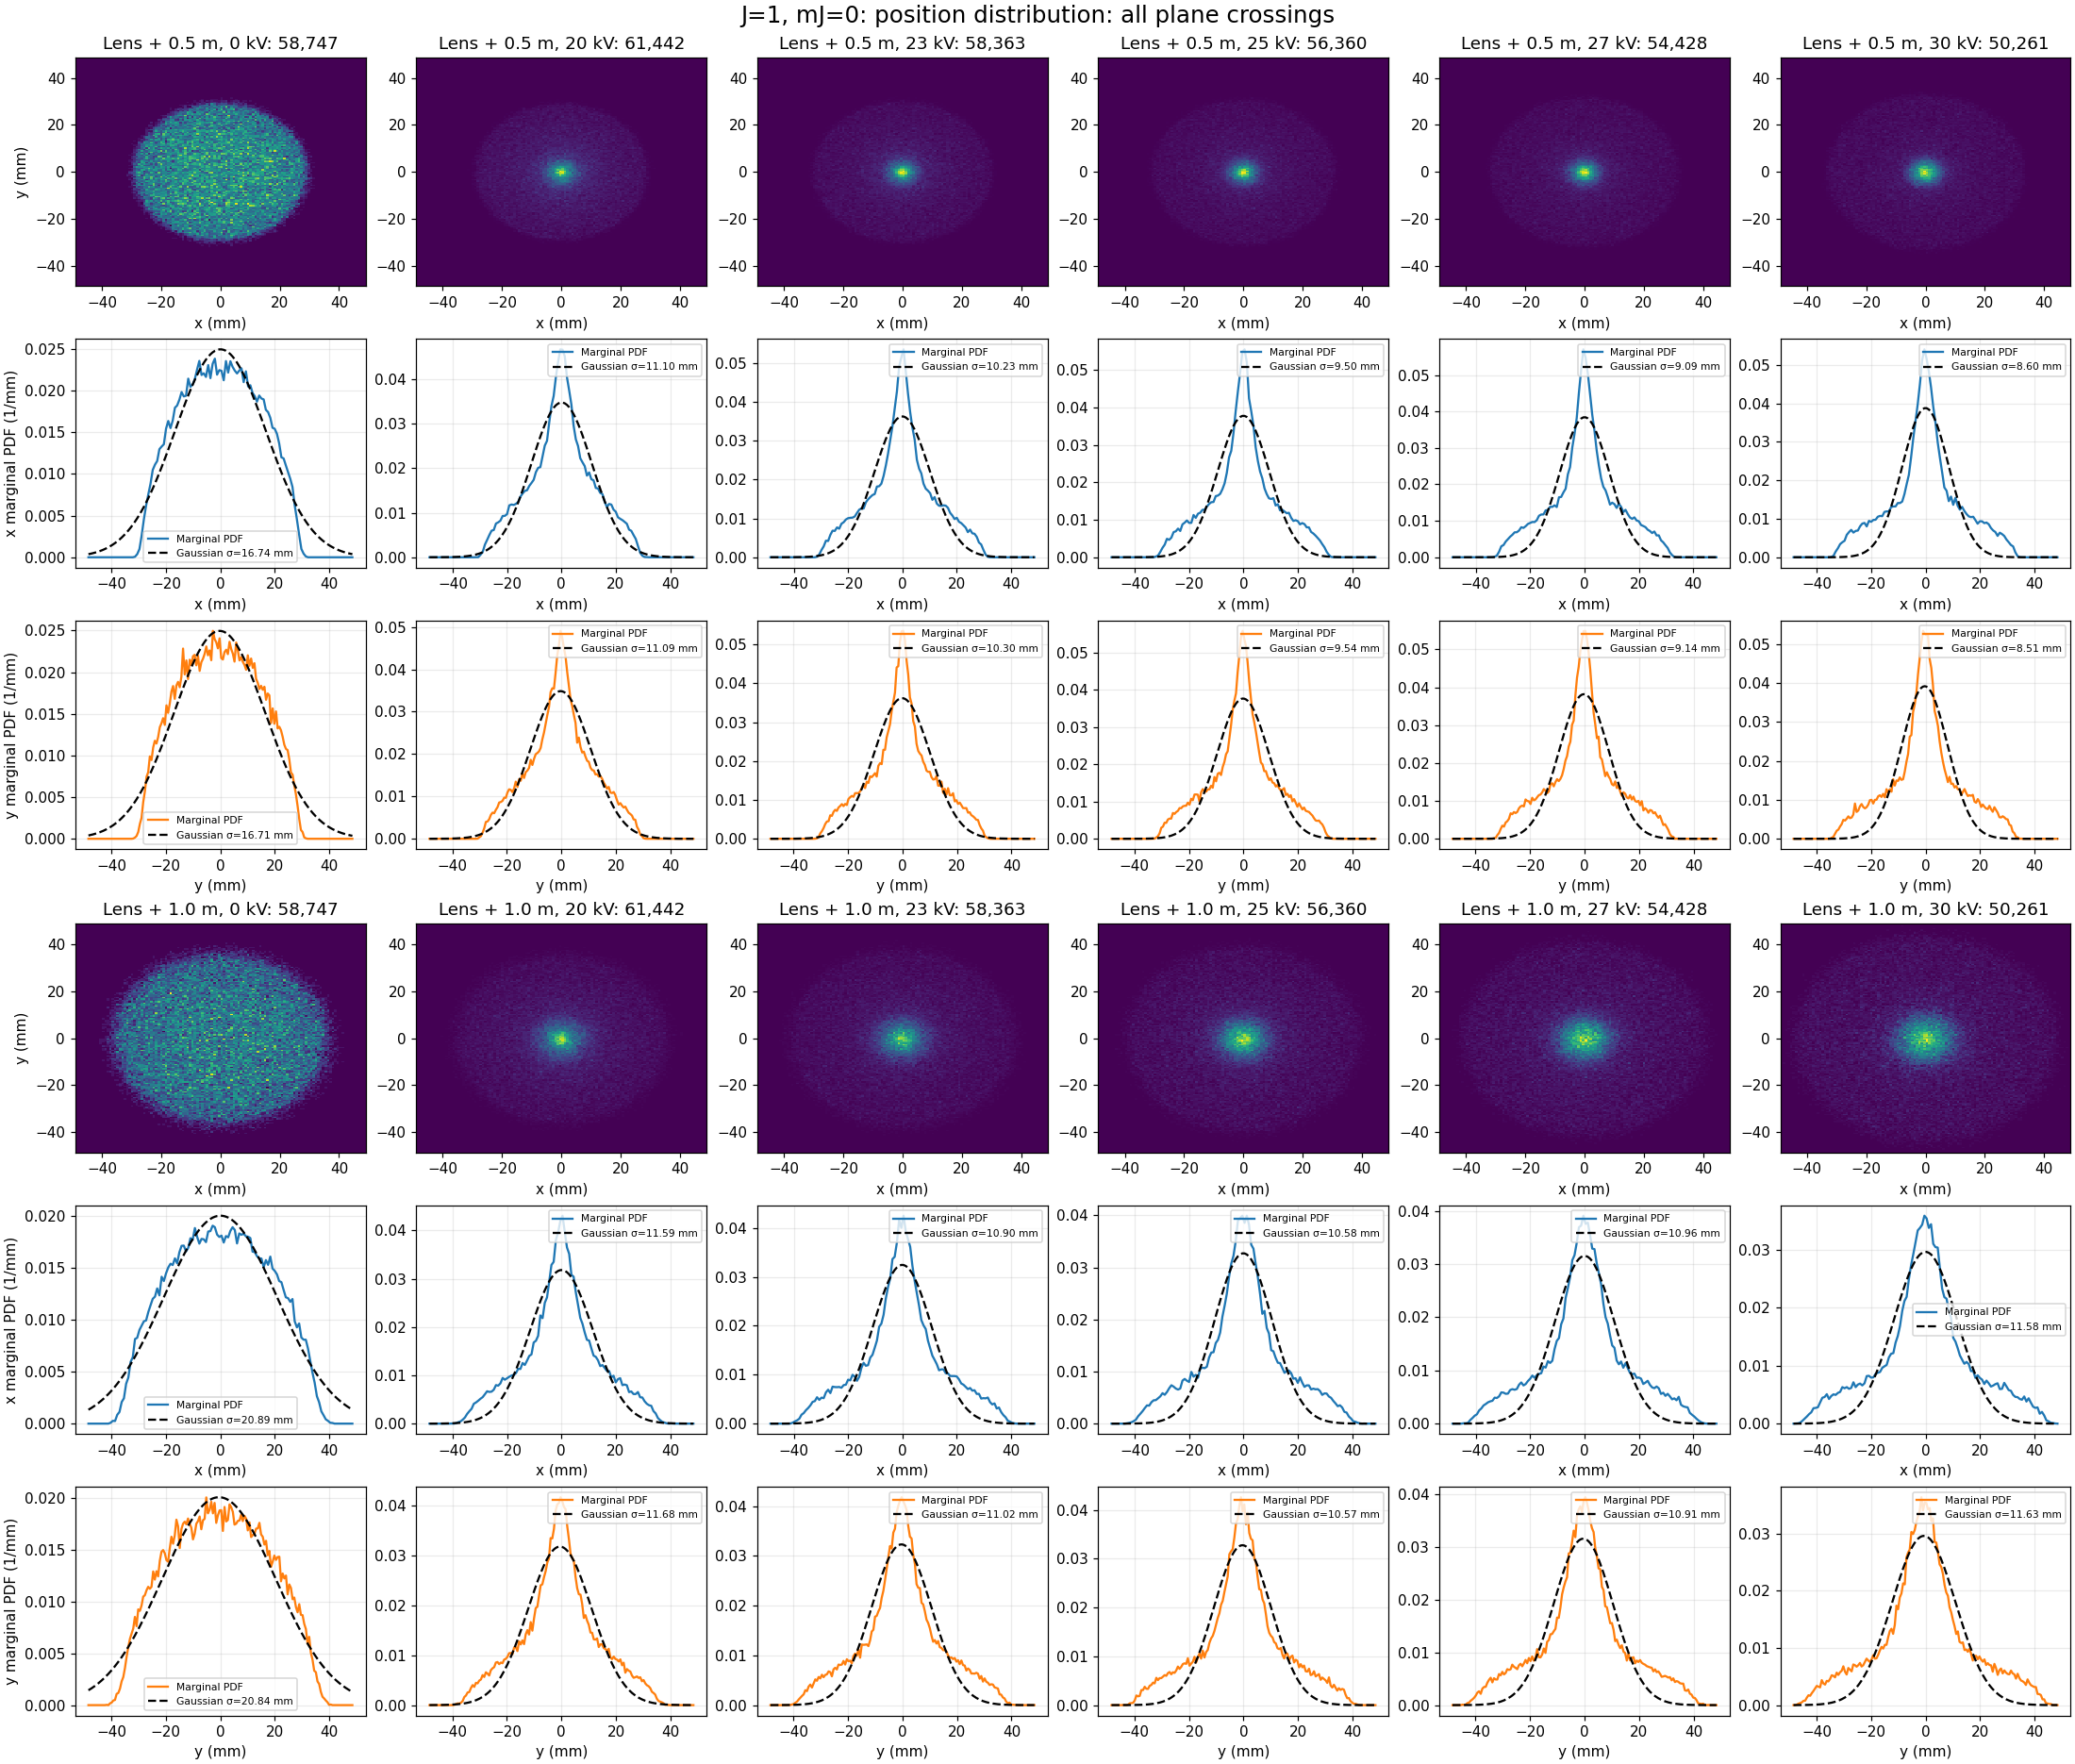

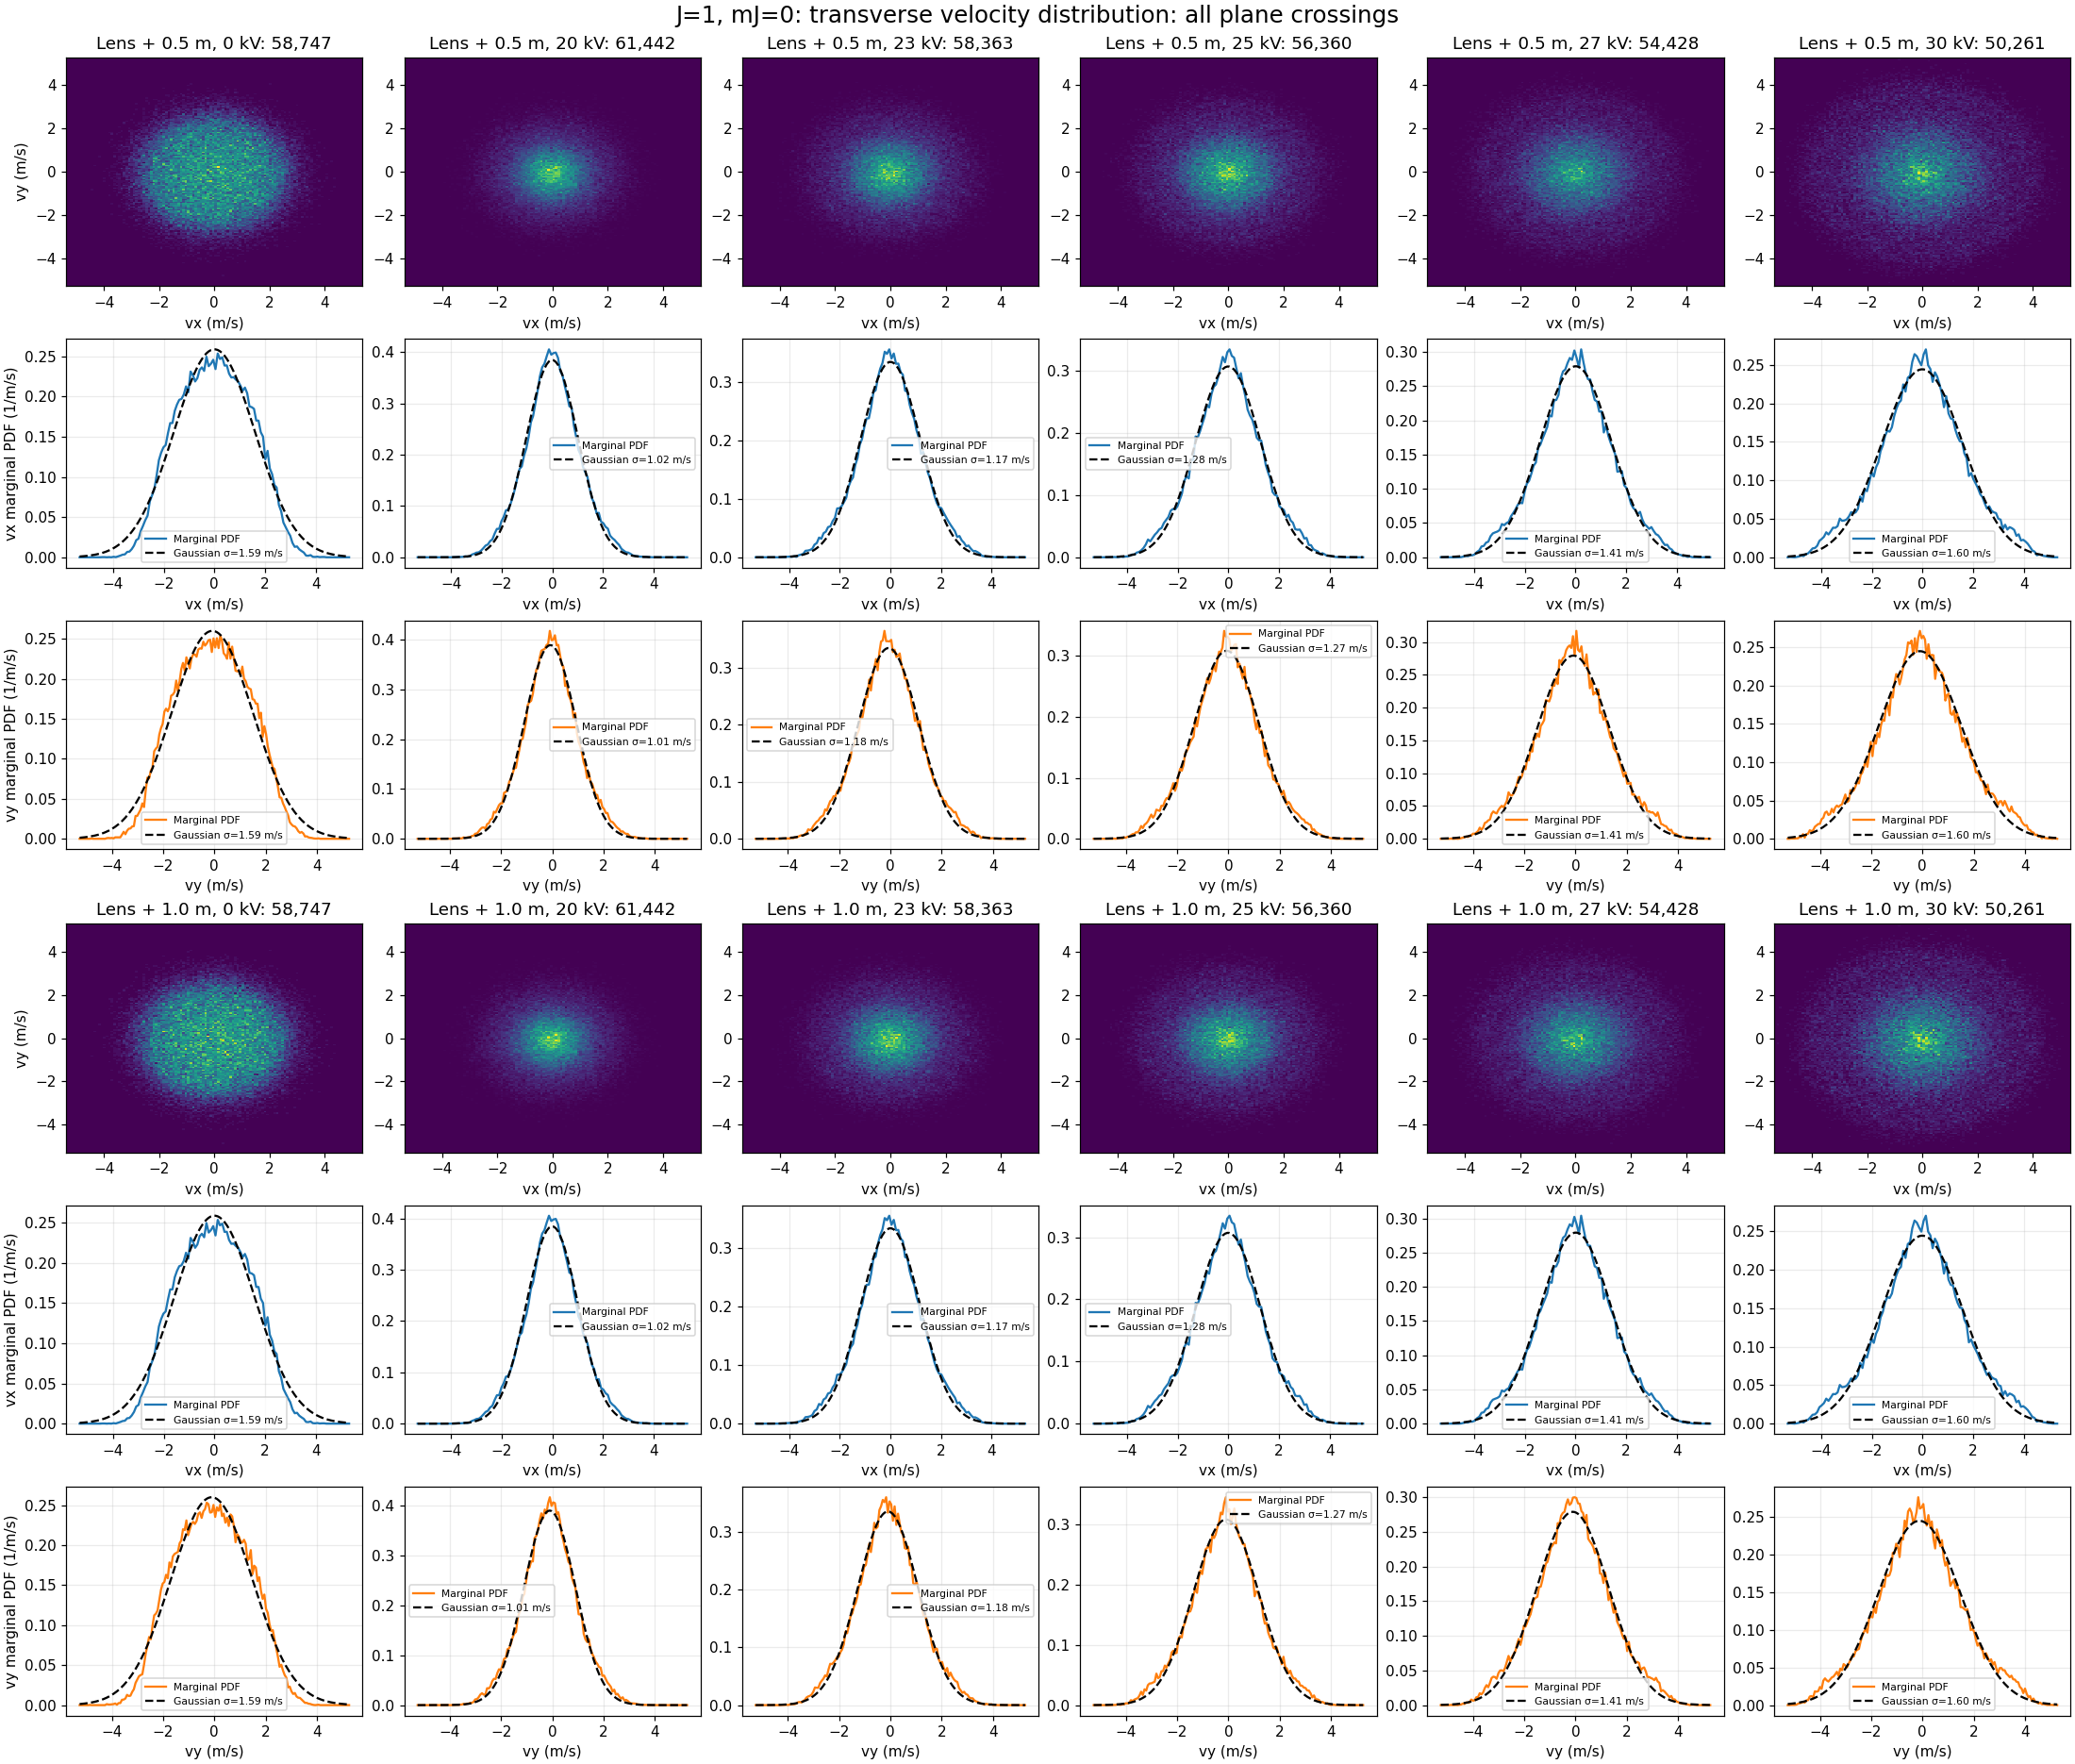

Plane,kV,Crossings,μx (mm),σx (mm),μy (mm),σy (mm)
Lens + 0.5 m,0,"58,747",0.025,16.743,-0.283,16.714
Lens + 0.5 m,20,"61,442",0.082,11.104,-0.307,11.086
Lens + 0.5 m,23,"58,363",-0.049,10.228,-0.119,10.302
Lens + 0.5 m,25,"56,360",-0.004,9.496,-0.158,9.543
Lens + 0.5 m,27,"54,428",0.032,9.087,-0.209,9.135
Lens + 0.5 m,30,"50,261",0.013,8.603,-0.300,8.511
Lens + 1.0 m,0,"58,747",0.030,20.887,-0.531,20.844
Lens + 1.0 m,20,"61,442",0.057,11.589,-0.547,11.678
Lens + 1.0 m,23,"58,363",-0.065,10.897,-0.344,11.021
Lens + 1.0 m,25,"56,360",-0.032,10.583,-0.368,10.574


Plane,kV,Crossings,μx (m/s),σx (m/s),μy (m/s),σy (m/s)
Lens + 0.5 m,0,"58,747",0.003,1.594,-0.081,1.587
Lens + 0.5 m,20,"61,442",-0.008,1.020,-0.079,1.006
Lens + 0.5 m,23,"58,363",0.001,1.175,-0.070,1.175
Lens + 0.5 m,25,"56,360",-0.009,1.280,-0.070,1.273
Lens + 0.5 m,27,"54,428",0.009,1.409,-0.082,1.406
Lens + 0.5 m,30,"50,261",-0.010,1.601,-0.096,1.604
Lens + 1.0 m,0,"58,747",0.003,1.594,-0.106,1.587
Lens + 1.0 m,20,"61,442",-0.008,1.020,-0.104,1.006
Lens + 1.0 m,23,"58,363",0.001,1.175,-0.095,1.175
Lens + 1.0 m,25,"56,360",-0.009,1.280,-0.094,1.274


J=1, mJ=1

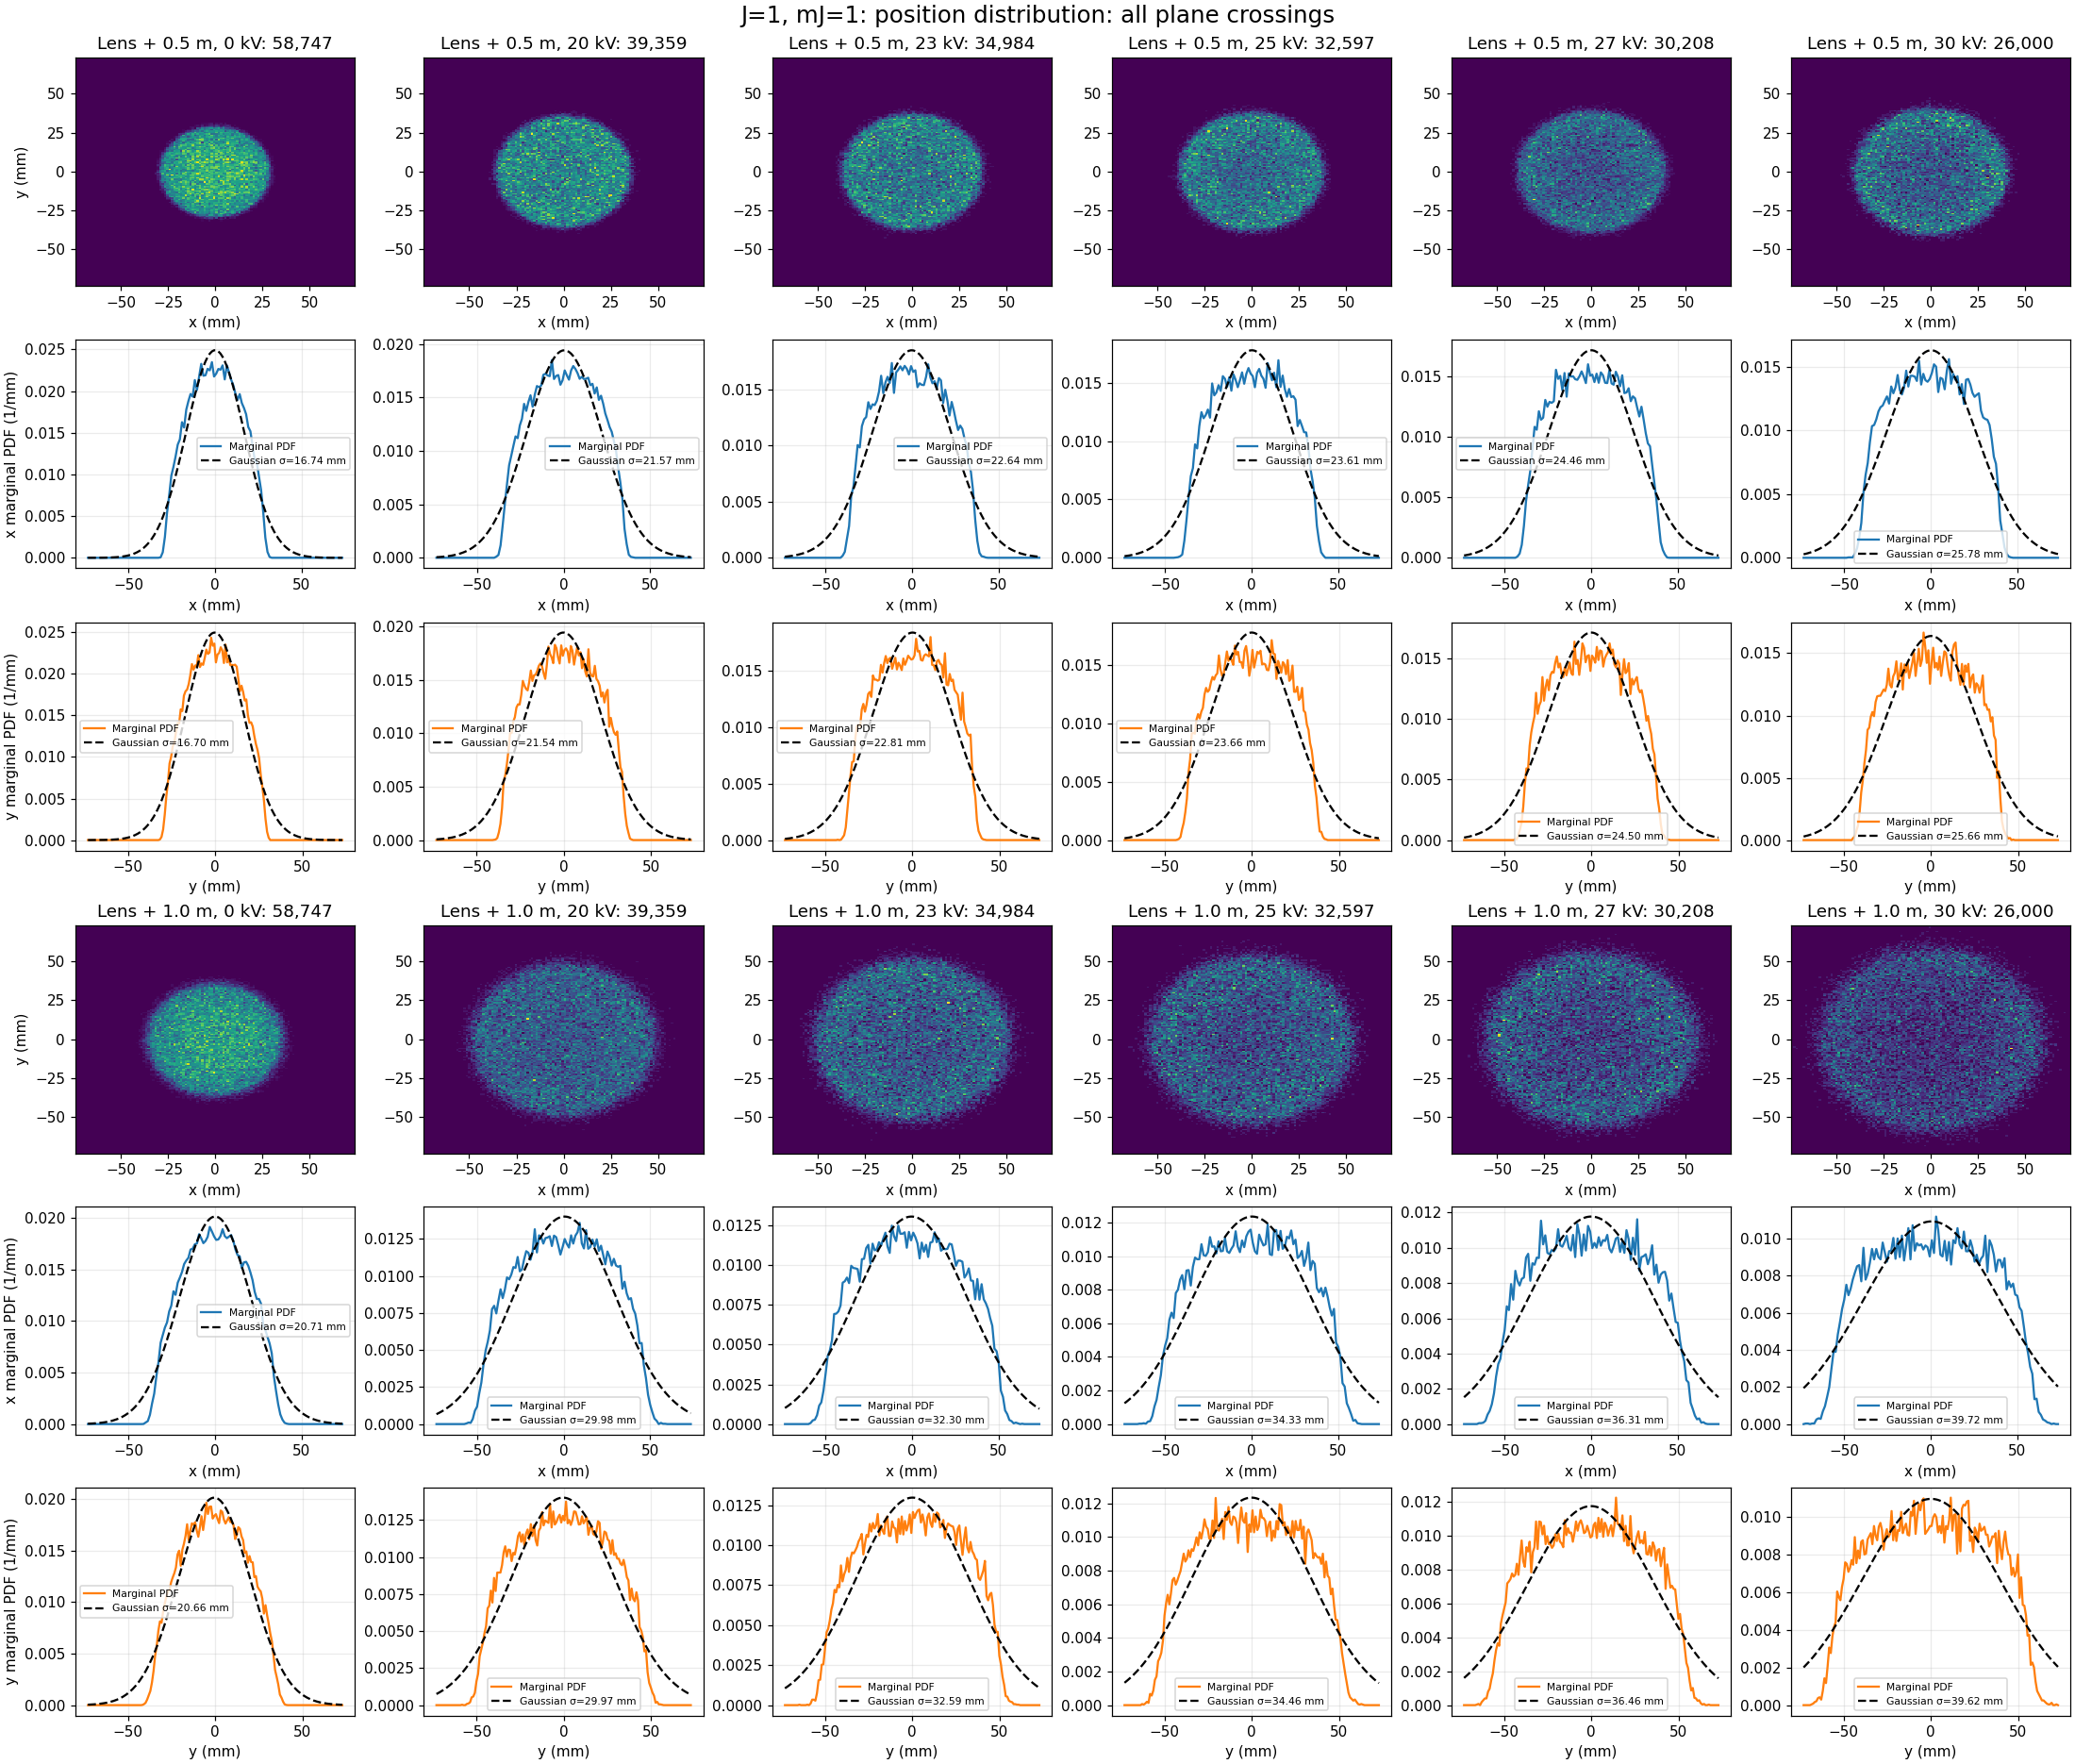

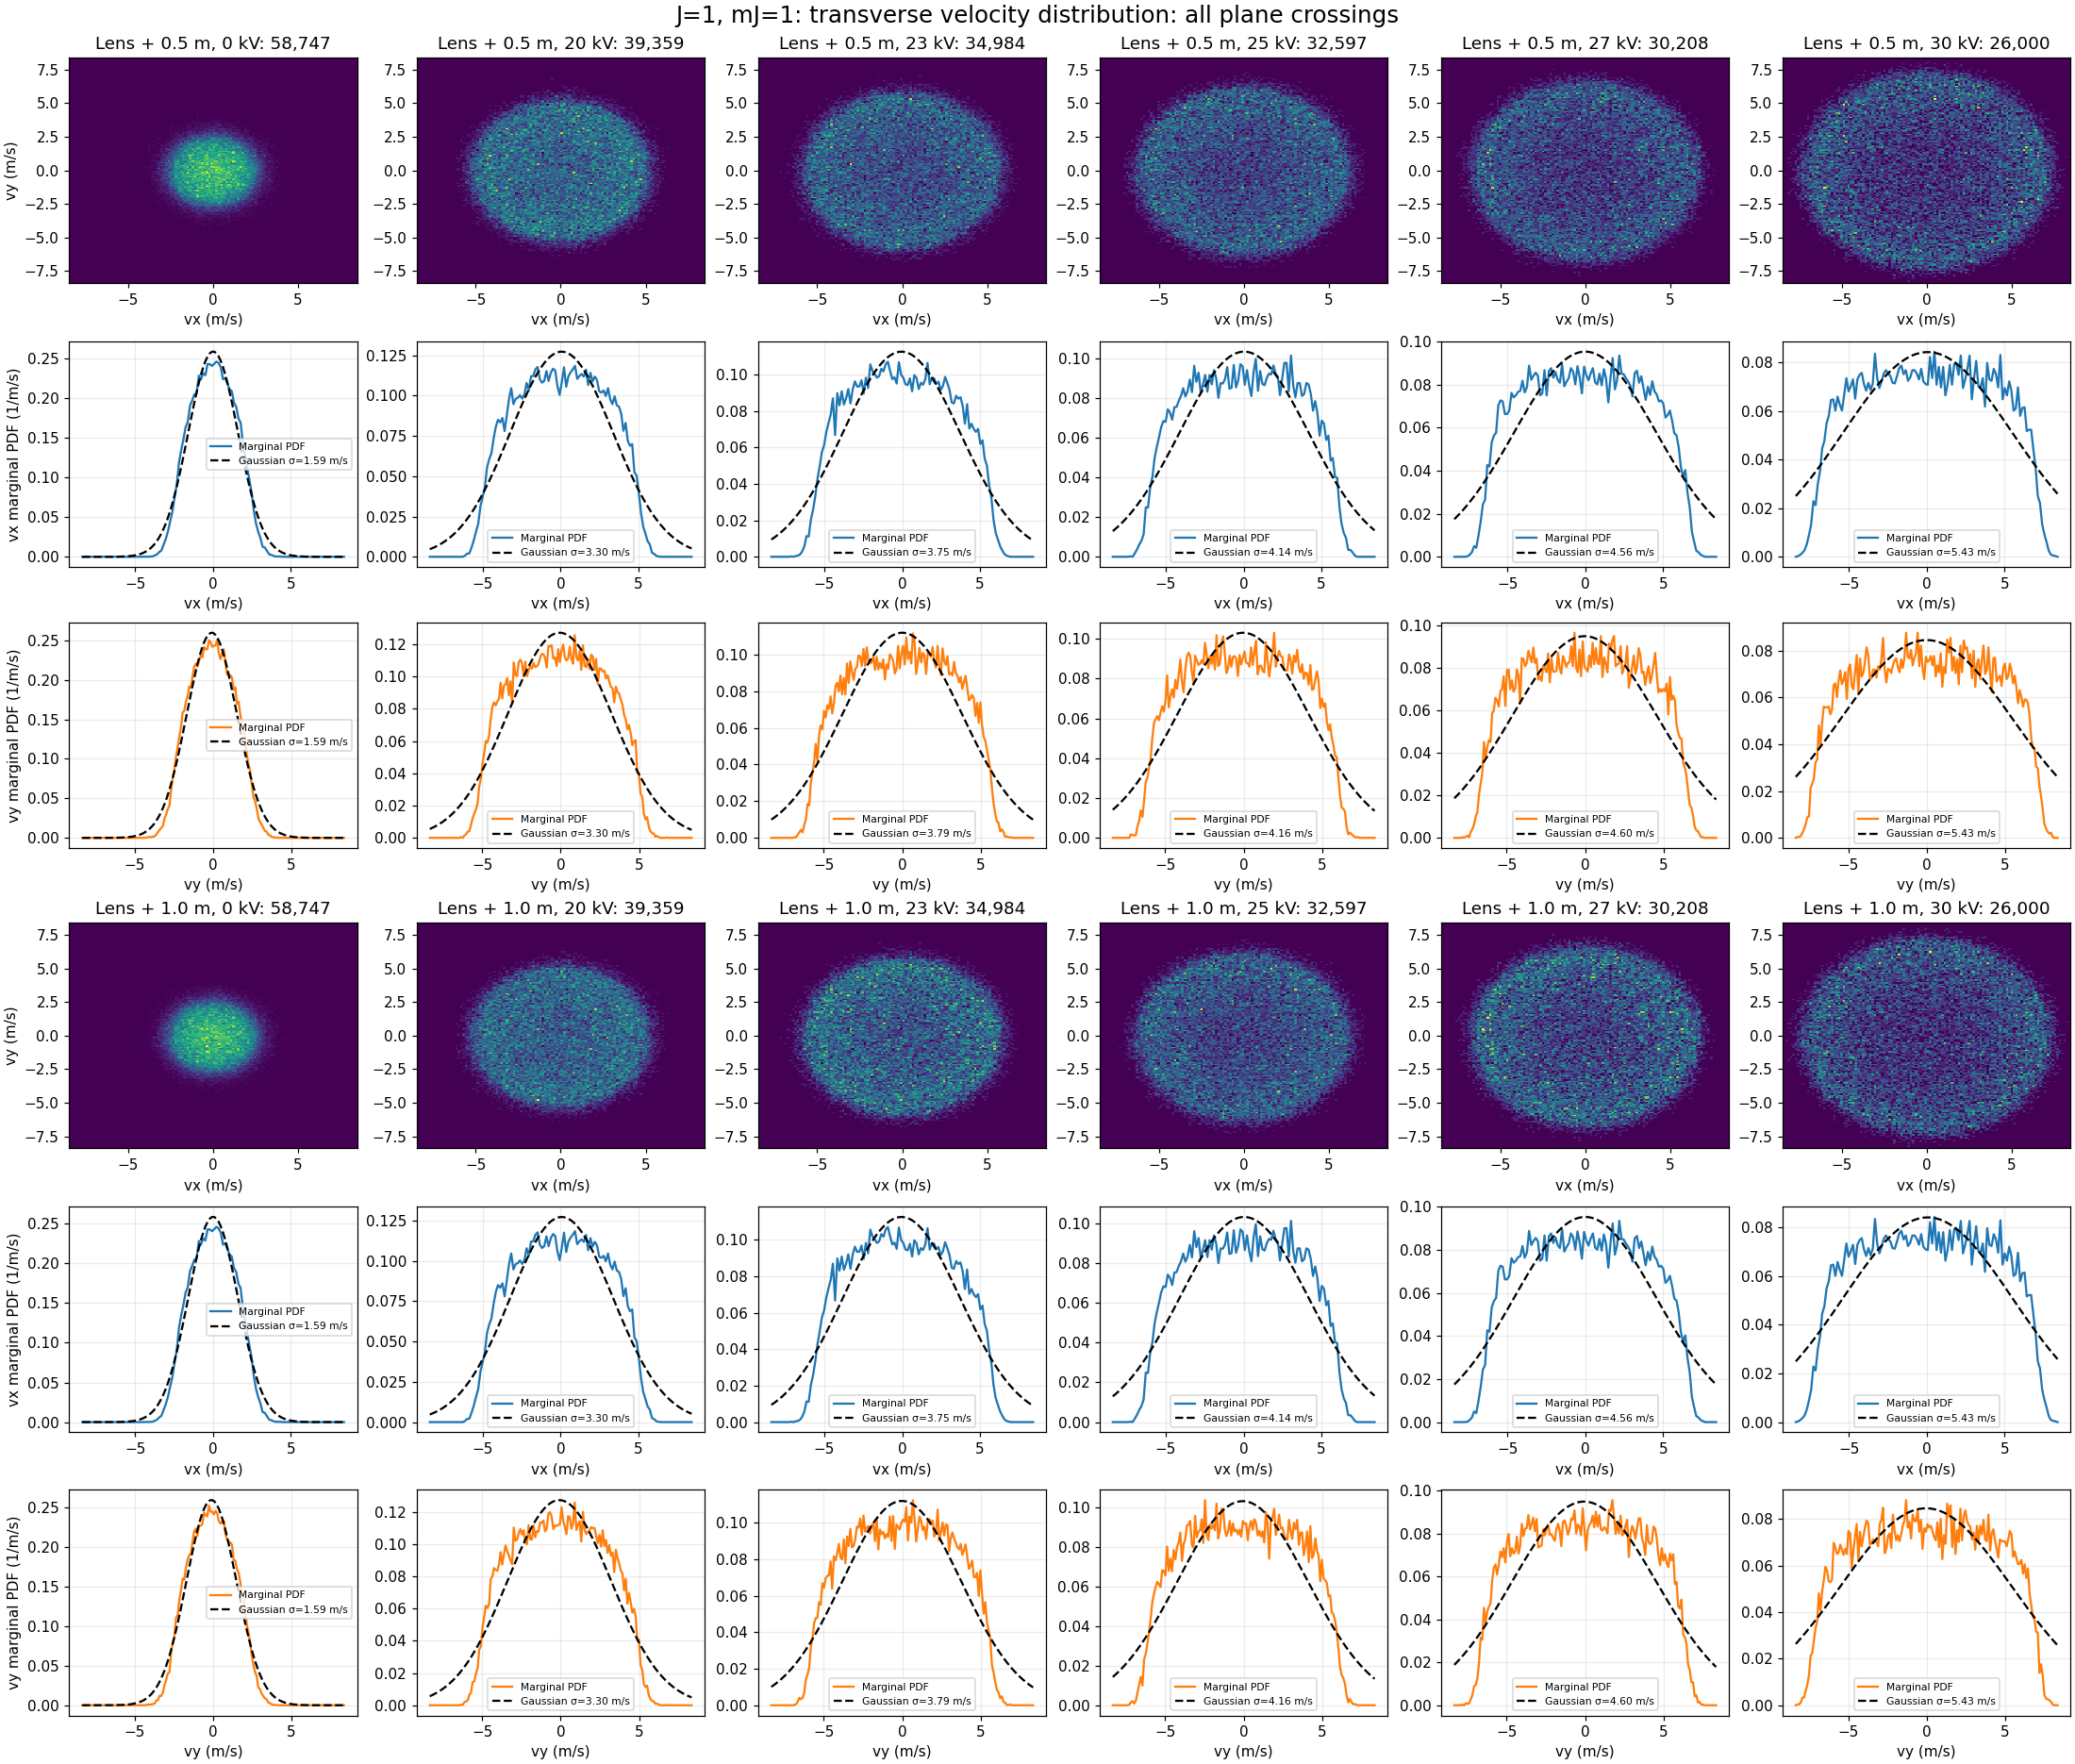

Plane,kV,Crossings,μx (mm),σx (mm),μy (mm),σy (mm)
Lens + 0.5 m,0,"58,747",0.022,16.738,-0.282,16.702
Lens + 0.5 m,20,"39,359",0.395,21.565,-0.159,21.536
Lens + 0.5 m,23,"34,984",-0.260,22.641,0.229,22.810
Lens + 0.5 m,25,"32,597",0.139,23.610,0.003,23.657
Lens + 0.5 m,27,"30,208",-0.006,24.459,0.011,24.497
Lens + 0.5 m,30,"26,000",0.267,25.776,0.186,25.657
Lens + 1.0 m,0,"58,747",0.031,20.711,-0.521,20.659
Lens + 1.0 m,20,"39,359",0.543,29.983,-0.364,29.971
Lens + 1.0 m,23,"34,984",-0.378,32.297,0.200,32.594
Lens + 1.0 m,25,"32,597",0.202,34.331,-0.134,34.462


Plane,kV,Crossings,μx (m/s),σx (m/s),μy (m/s),σy (m/s)
Lens + 0.5 m,0,"58,747",0.002,1.594,-0.080,1.587
Lens + 0.5 m,20,"39,359",0.059,3.298,-0.067,3.301
Lens + 0.5 m,23,"34,984",-0.046,3.755,-0.002,3.788
Lens + 0.5 m,25,"32,597",0.027,4.137,-0.042,4.159
Lens + 0.5 m,27,"30,208",0.001,4.563,-0.040,4.595
Lens + 0.5 m,30,"26,000",0.064,5.432,-0.006,5.430
Lens + 1.0 m,0,"58,747",0.002,1.594,-0.106,1.587
Lens + 1.0 m,20,"39,359",0.059,3.298,-0.091,3.301
Lens + 1.0 m,23,"34,984",-0.046,3.755,-0.027,3.788
Lens + 1.0 m,25,"32,597",0.027,4.137,-0.069,4.159


In [6]:
from scipy.optimize import curve_fit
from scipy.stats import norm
from IPython.display import HTML, display

PLANE_NAMES = (("lens_plus_0p5m", "Lens + 0.5 m"),
               ("lens_plus_1p0m", "Lens + 1.0 m"))

def fit_plane_marginal(centers, pdf):
    if np.count_nonzero(pdf) < 4:
        return None
    weights = pdf / pdf.sum()
    mean = float(np.sum(centers * weights))
    width = max(float(np.sqrt(np.sum(weights * (centers - mean) ** 2))), 1e-3)
    try:
        parameters, _ = curve_fit(
            lambda value, amplitude, mu, sigma: amplitude * norm.pdf(value, mu, sigma),
            centers, pdf, p0=(1.0, mean, width),
            bounds=([0.0, -np.inf, 1e-9], [np.inf, np.inf, np.inf]),
            maxfev=10000,
        )
    except (RuntimeError, ValueError):
        return None
    return tuple(float(value) for value in parameters)

def plot_plane_quantity(planes_file, x_field, y_field, unit, scale, title):
    records = {}
    x_limit = y_limit = 1.0
    for plane_name, _ in PLANE_NAMES:
        for kv in VOLTAGES_KV:
            group = planes_file[f"{kv}kV/{plane_name}"]
            x = group[x_field][:] * scale
            y = group[y_field][:] * scale
            records[(plane_name, kv)] = (x, y)
            if len(x):
                x_limit = max(x_limit, float(np.max(np.abs(x))))
                y_limit = max(y_limit, float(np.max(np.abs(y))))
    x_edges = np.linspace(-1.02 * x_limit, 1.02 * x_limit, 121)
    y_edges = np.linspace(-1.02 * y_limit, 1.02 * y_limit, 161)
    fig, axes = plt.subplots(6, len(VOLTAGES_KV), figsize=(20, 17),
                             constrained_layout=True)
    fitted = {}
    for plane_row, (plane_name, plane_label) in enumerate(PLANE_NAMES):
        for col, kv in enumerate(VOLTAGES_KV):
            x, y = records[(plane_name, kv)]
            map_ax, x_ax, y_ax = axes[3 * plane_row:3 * plane_row + 3, col]
            map_ax.set_title(f"{plane_label}, {kv} kV: {len(x):,}")
            map_ax.set_xlabel(f"{x_field} ({unit})")
            x_ax.set_xlabel(f"{x_field} ({unit})")
            y_ax.set_xlabel(f"{y_field} ({unit})")
            if col == 0:
                map_ax.set_ylabel(f"{y_field} ({unit})")
                x_ax.set_ylabel(f"{x_field} marginal PDF (1/{unit})")
                y_ax.set_ylabel(f"{y_field} marginal PDF (1/{unit})")
            if len(x) == 0:
                map_ax.text(0.5, 0.5, "No crossings", ha="center",
                            transform=map_ax.transAxes)
                fitted[(plane_name, kv)] = (0, None, None)
                continue
            plt.sca(map_ax)
            pdf_2d, xe, ye, _ = plt.hist2d(x, y, bins=(x_edges, y_edges),
                                           density=True, cmap="viridis")
            x_centers = (xe[:-1] + xe[1:]) / 2
            y_centers = (ye[:-1] + ye[1:]) / 2
            pdf_x = (pdf_2d * np.diff(ye)[None, :]).sum(axis=1)
            pdf_y = (pdf_2d * np.diff(xe)[:, None]).sum(axis=0)
            fits = []
            for ax, centers, pdf, color in ((x_ax, x_centers, pdf_x, "C0"),
                                             (y_ax, y_centers, pdf_y, "C1")):
                ax.plot(centers, pdf, color=color, label="Marginal PDF")
                fit = fit_plane_marginal(centers, pdf)
                fits.append(fit)
                if fit is not None:
                    amplitude, mu, sigma = fit
                    ax.plot(centers, amplitude * norm.pdf(centers, mu, sigma),
                            "--", color="k", label=f"Gaussian σ={sigma:.2f} {unit}")
                ax.grid(alpha=0.25)
                ax.legend(fontsize=7)
            fitted[(plane_name, kv)] = (len(x), fits[0], fits[1])
    fig.suptitle(f"{title}: all plane crossings", fontsize=16)
    plt.show()
    return fitted

def show_plane_summary(title, fits, unit):
    rows = [f"<tr><th>Plane</th><th>kV</th><th>Crossings</th>"
            f"<th>μx ({unit})</th><th>σx ({unit})</th>"
            f"<th>μy ({unit})</th><th>σy ({unit})</th></tr>"]
    for plane_name, plane_label in PLANE_NAMES:
        for kv in VOLTAGES_KV:
            count, fx, fy = fits[(plane_name, kv)]
            def number(fit, parameter):
                return f"{fit[parameter]:.3f}" if fit is not None else "—"
            rows.append(f"<tr><td>{plane_label}</td><td>{kv}</td><td>{count:,}</td>"
                        f"<td>{number(fx, 1)}</td><td>{number(fx, 2)}</td>"
                        f"<td>{number(fy, 1)}</td><td>{number(fy, 2)}</td></tr>")
    display(HTML(f"<h3>{title}</h3><table>{''.join(rows)}</table>"))

for mJ in (0, 1):
    PLANES_H5 = state_path(mJ)
    display(HTML(f"<h2>J=1, mJ={mJ}</h2>"))
    with h5py.File(PLANES_H5, "r") as planes_file:
        position_fits = plot_plane_quantity(planes_file, "x", "y", "mm", 1e3,
                                            f"J=1, mJ={mJ}: position distribution")
        velocity_fits = plot_plane_quantity(planes_file, "vx", "vy", "m/s", 1.0,
                                            f"J=1, mJ={mJ}: transverse velocity distribution")
    show_plane_summary(f"J=1, mJ={mJ}: position Gaussian fits", position_fits, "mm")
    show_plane_summary(f"J=1, mJ={mJ}: velocity Gaussian fits", velocity_fits, "m/s")
